#### Import Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression



#### Load Dataset

In [2]:
student_ds = pd.read_csv("StudentPerformanceFactors.csv")
print(student_ds)
student_ds.columns.tolist()

      Hours_Studied  Attendance Parental_Involvement Access_to_Resources  \
0                23          84                  Low                High   
1                19          64                  Low              Medium   
2                24          98               Medium              Medium   
3                29          89                  Low              Medium   
4                19          92               Medium              Medium   
...             ...         ...                  ...                 ...   
6602             25          69                 High              Medium   
6603             23          76                 High              Medium   
6604             20          90               Medium                 Low   
6605             10          86                 High                High   
6606             15          67               Medium                 Low   

     Extracurricular_Activities  Sleep_Hours  Previous_Scores  \
0                     

['Hours_Studied',
 'Attendance',
 'Parental_Involvement',
 'Access_to_Resources',
 'Extracurricular_Activities',
 'Sleep_Hours',
 'Previous_Scores',
 'Motivation_Level',
 'Internet_Access',
 'Tutoring_Sessions',
 'Family_Income',
 'Teacher_Quality',
 'School_Type',
 'Peer_Influence',
 'Physical_Activity',
 'Learning_Disabilities',
 'Parental_Education_Level',
 'Distance_from_Home',
 'Gender',
 'Exam_Score']

In [3]:
#check the first 0 students
student_ds.head(10)

#check for empty values
student_ds.isnull().sum()

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

In [4]:
student_ds.nunique()

Hours_Studied                 41
Attendance                    41
Parental_Involvement           3
Access_to_Resources            3
Extracurricular_Activities     2
Sleep_Hours                    7
Previous_Scores               51
Motivation_Level               3
Internet_Access                2
Tutoring_Sessions              9
Family_Income                  3
Teacher_Quality                3
School_Type                    2
Peer_Influence                 3
Physical_Activity              7
Learning_Disabilities          2
Parental_Education_Level       3
Distance_from_Home             3
Gender                         2
Exam_Score                    45
dtype: int64

In [5]:
student_ds.describe()


,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


In [6]:
student_ds.info()

<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   str  
 8   Internet_Access             6607 non-null   str  
 9   Tutoring_Sessions           6607 non-null   int64
 10  Family_Income               6607 non-null   str  
 11  Teacher_Quality             6529 non-null   str  
 12  School_Type                 6607 non-null   str  
 13  Peer_Influence              6607 non-null   str  
 14  Physical_Activity  

* Inspecting Correleation

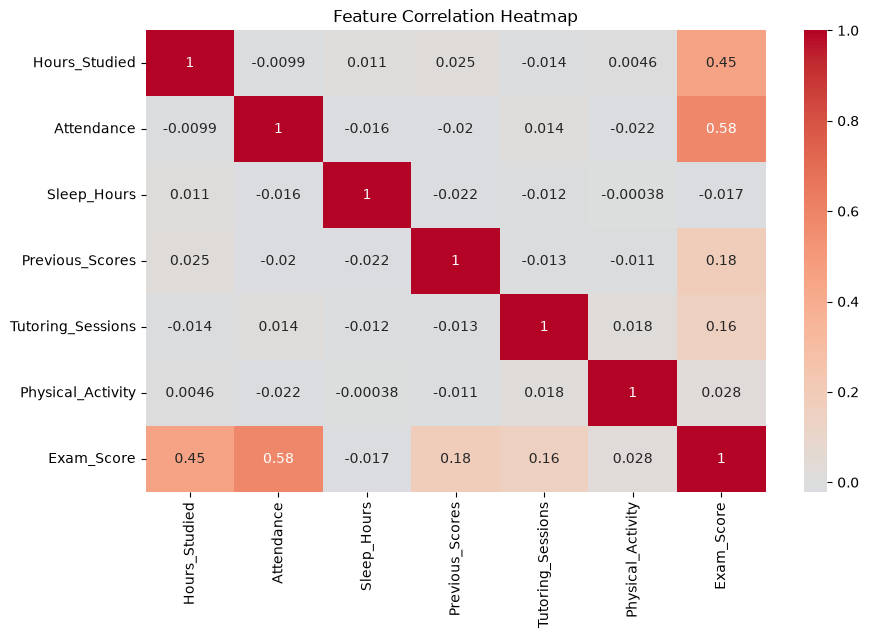

In [7]:
plt.figure(figsize=(10, 6))

# Select only numeric columns for correlation
cols = student_ds.select_dtypes(include=['float64', 'int64']).columns
sns.heatmap(student_ds[cols].corr(), annot=True, cmap='coolwarm', center=0)
plt.title("Feature Correlation Heatmap")
plt.show()

#### Feature Engineering

In [8]:
#inspecting columns
student_ds.columns.tolist()

# selecting the features
X = student_ds[['Hours_Studied',
'Access_to_Resources',
'Attendance',
'Tutoring_Sessions',
'Previous_Scores',

]]

#selecting the target variable
y = student_ds['Exam_Score']


#inspecting selected features
print(f"first 10 rows: \n {X.head(10)}\n")
print(f"shape of the df : \n{X.shape}\n")
print(f"number of unique values:\n {X.nunique()}")


first 10 rows: 
    Hours_Studied Access_to_Resources  Attendance  Tutoring_Sessions  \
0             23                High          84                  0   
1             19              Medium          64                  2   
2             24              Medium          98                  2   
3             29              Medium          89                  1   
4             19              Medium          92                  3   
5             19              Medium          88                  3   
6             29                 Low          84                  1   
7             25                High          78                  1   
8             17                High          94                  0   
9             23              Medium          98                  0   

   Previous_Scores  
0               73  
1               59  
2               91  
3               98  
4               65  
5               89  
6               68  
7               50  
8           

* Encoding Categorical data to Numerical

In [9]:
from sklearn.preprocessing import OneHotEncoder

#initialize one hot encoder
encoder = OneHotEncoder(drop = 'first', handle_unknown='ignore', sparse_output=False)

#encoding the specific columns
encoded = encoder.fit_transform(X[['Access_to_Resources']])


#confirming the one-hot encoding works 
print(encoded[:5])
X.columns.tolist()


[[0. 0.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]]


['Hours_Studied',
 'Access_to_Resources',
 'Attendance',
 'Tutoring_Sessions',
 'Previous_Scores']

In [10]:
# Remove the original categorical column
X = X.drop(columns=['Access_to_Resources'])

# Add the encoded columns
X[encoder.get_feature_names_out()] = encoded

#inspecting the new encoded columns
X.columns.tolist()
X.dtypes
X.head()




,Hours_Studied,Attendance,Tutoring_Sessions,Previous_Scores,Access_to_Resources_Low,Access_to_Resources_Medium
0,23,84,0,73,0.0,0.0
1,19,64,2,59,0.0,1.0
2,24,98,2,91,0.0,1.0
3,29,89,1,98,0.0,1.0
4,19,92,3,65,0.0,1.0


#### Split Dataset

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y,test_size = 0.2, random_state= 42
    )


In [12]:
print(f"X_train : {X_train.shape}")
print(f"X_test : {X_test.shape}")
print(f"y_train : {y_train.shape}")
print(f"y_test : {y_test.shape}")

X_train : (5285, 6)
X_test : (1322, 6)
y_train : (5285,)
y_test : (1322,)


#### Train Model

In [13]:
#initializing algorithm

regressor = LinearRegression()
regressor.fit(X_train,y_train)

print(X.dtypes)

Hours_Studied                   int64
Attendance                      int64
Tutoring_Sessions               int64
Previous_Scores                 int64
Access_to_Resources_Low       float64
Access_to_Resources_Medium    float64
dtype: object


**predict target(y_test)**

In [14]:
prediction = regressor.predict(X_test)
print(f"Actual prediction :\n{y_test.head(10)}")
print(f"Predicted values :\n{prediction.round()[:10]}")

Actual prediction :
743     65
5551    65
3442    71
6571    64
4204    66
2516    66
4047    72
1706    66
1075    70
233     70
Name: Exam_Score, dtype: int64
Predicted values :
[65. 66. 68. 66. 66. 68. 71. 67. 68. 69.]


#### Visualize Model

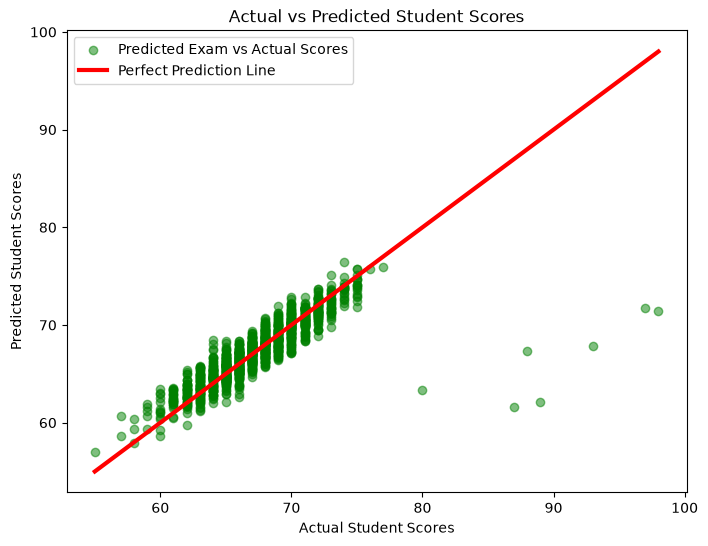

In [15]:
plt.figure(figsize =(8,6))
plt.scatter(y_test, prediction, alpha= 0.5, color = "green",label = "Predicted Exam vs Actual Scores")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r", lw=3, label="Perfect Prediction Line")
plt.xlabel("Actual Student Scores")
plt.ylabel("Predicted Student Scores")
plt.title("Actual vs Predicted Student Scores")
plt.legend()


plt.show()

#### Evaluate Model

 * **checking the absolute difference of model**

In [16]:
#creating a comparison table of actual values and predictions 
compare_table = pd.DataFrame({"Actual values(y_test)":y_test,"Predicted_values":prediction})

#calculating the absolute difference between actual values and predicted values
abs_diff = pd.DataFrame({"Absolute Difference" : abs(y_test - prediction)})

compare_table = compare_table.join(abs_diff)
compare_table


,Actual values(y_test),Predicted_values,Absolute Difference
743,65,64.673404,0.326596
5551,65,66.284103,1.284103
3442,71,68.345148,2.654852
6571,64,65.533481,1.533481
4204,66,66.235177,0.235177
...,...,...,...
4709,69,66.976370,2.023630
3664,72,72.174407,0.174407
5231,66,65.524712,0.475288
1773,63,65.735658,2.735658


In [17]:
#minimum and max of actual and predicted values
print("*"*50)
print(f"The maximum value of actual values\n {compare_table['Actual values(y_test)'].max()}")
print(f"The minimum value of actual values\n {compare_table['Actual values(y_test)'].min()}")

print("*"*50)
print(f"The maximum value of predicted values\n {compare_table['Predicted_values'].max()}")
print(f"The minimum value of predicted values\n {compare_table['Predicted_values'].min()}")
print("*"*50)


**************************************************
The maximum value of actual values
 98
The minimum value of actual values
 55
**************************************************
The maximum value of predicted values
 76.48918505603784
The minimum value of predicted values
 57.01376632908446
**************************************************


*  MSE : Mean Squared Error

In [18]:
#import MSE from scikit learn library
from sklearn.metrics import mean_squared_error

#calculate mean squared error
MSE = mean_squared_error(
    compare_table["Actual values(y_test)"],
    compare_table["Predicted_values"]
    )

print(f"mean squared error is {round(MSE,3)}")

mean squared error is 4.59


In [19]:
#calculating RMSE
RMSE = np.sqrt(MSE)
print(f"Root mean sqaured error is {round(RMSE,3)}")

Root mean sqaured error is 2.142


* Range of Correct Actual Values

In [20]:
#creating a range with the rmse
compare_table["Highest Score"] = compare_table["Predicted_values"]+RMSE
compare_table["Lowest Score"] = compare_table["Predicted_values"] -RMSE

compare_table

,Actual values(y_test),Predicted_values,Absolute Difference,Highest Score,Lowest Score
743,65,64.673404,0.326596,66.815857,62.530951
5551,65,66.284103,1.284103,68.426556,64.141649
3442,71,68.345148,2.654852,70.487601,66.202694
6571,64,65.533481,1.533481,67.675934,63.391028
4204,66,66.235177,0.235177,68.377630,64.092724
...,...,...,...,...,...
4709,69,66.976370,2.023630,69.118824,64.833917
3664,72,72.174407,0.174407,74.316860,70.031954
5231,66,65.524712,0.475288,67.667166,63.382259
1773,63,65.735658,2.735658,67.878111,63.593205


* MAE : Mean Absolute Error

In [21]:
#mean absolute error from sklearn
from sklearn.metrics import mean_absolute_error

MAE = mean_absolute_error(compare_table["Actual values(y_test)"],compare_table["Predicted_values"])
print(f"Mean Absolute error : {round(MAE, 3)}")

Mean Absolute error : 1.119


* R-Squared Value

In [22]:
#calculating R-Squared 
from sklearn.metrics import r2_score
r_squared = r2_score(compare_table["Actual values(y_test)"],compare_table["Predicted_values"])
print(f"r_squared: {r_squared}")

r_squared: 0.6752683741589374


### POLYNOMIAL REGRESSION

In [23]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

##### Select Features 

In [24]:
added_features =[
    'Hours_Studied', 
    'Attendance', 
    'Sleep_Hours',
    'Previous_Scores',
    'Tutoring_Sessions',
    'Physical_Activity',
]
X = student_ds[added_features]

y = student_ds['Exam_Score']


#### Split The Data

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size= 0.2, random_state= 42
    )

In [26]:
print(f'X_train : {X_train.shape}')
print(f'X_test : {X_test.shape}')
print(f'y_train : {y_train.shape}')
print(f'y_test : {y_test.shape}')
X.head()

X_train : (5285, 6)
X_test : (1322, 6)
y_train : (5285,)
y_test : (1322,)


,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity
0,23,84,7,73,0,3
1,19,64,8,59,2,4
2,24,98,7,91,2,4
3,29,89,8,98,1,4
4,19,92,6,65,3,4


#### Creating Polynomial Features

In [27]:
poly = PolynomialFeatures(degree = 2, include_bias =False)

* Transform Training and Testing Data

In [28]:
x_train_poly = poly.fit_transform(X_train) #learns from x_train and creates polynomial features

x_test_poly = poly.transform(X_test) # creates polynomial featureson x_test

In [29]:
poly_model = LinearRegression()

#trains the model using the polynomial training features
#  and the the actual exam training score(y_train)

poly_model.fit(x_train_poly, y_train) 

#making predictions

poly_predictions = poly_model.predict(x_test_poly)

* Inspect predictions

In [30]:
print(poly_predictions[:10])
print(y_test.head(10))

[66.06458181 67.26430895 68.40704097 66.63773908 65.61048102 67.95985767
 70.17879243 67.31319424 68.53543018 67.70986831]
743     65
5551    65
3442    71
6571    64
4204    66
2516    66
4047    72
1706    66
1075    70
233     70
Name: Exam_Score, dtype: int64


#### Evaluate Model

* MSE : Mean Squared Error

In [31]:
poly_mse = mean_squared_error(y_test,poly_predictions)
poly_mse

5.100624601565941

* RMSE 

In [32]:
poly_rmse = np.sqrt(poly_mse)
poly_rmse

np.float64(2.2584562430044866)

* R_Squared Value

In [33]:
poly_r2 = r2_score(y_test,poly_predictions)
poly_r2

0.639151153183775

* MAE : Mean Absolute Error


In [34]:
poly_mae = mean_absolute_error(y_test,poly_predictions)
poly_mae

1.2729176994233744

### MODEL COMPARISON

In [35]:
print("Original Linear Regression MSE:", MSE)
print("Polynomial Regression MSE:", poly_mse)
print()
print("Original Linear Regression RMSE:",RMSE)
print("Polynomial Regression RMSE: ",poly_rmse)
print()
print("Original Linear Regression R²:", r_squared)
print("Polynomial Regression R²:", poly_r2)
print()
print("Original Linear Regression MAE:", MAE)
print("Polynomial Regression MAE: ",poly_mae )

Original Linear Regression MSE: 4.59010506555665
Polynomial Regression MSE: 5.100624601565941

Original Linear Regression RMSE: 2.1424530486236217
Polynomial Regression RMSE:  2.2584562430044866

Original Linear Regression R²: 0.6752683741589374
Polynomial Regression R²: 0.639151153183775

Original Linear Regression MAE: 1.1185039307948565
Polynomial Regression MAE:  1.2729176994233744


## Conclusion & Key Takeaways

* **Winning Model:** The original **Linear Regression model performed better** across all evaluation metrics, achieving an $R^2$ score of **0.6753** compared to the Polynomial Regression model's **0.6392**.
* **Complexity vs. Performance:** Introducing polynomial features (Degree 2) increased model complexity but did not improve predictive power in this experiment.
* **Data Nuance:** Because the two models used different feature sets, the lower performance in the second model could stem from either the polynomial transformation or the exclusion of the categorical `Access_to_Resources` feature.

### Final Metrics Comparison:

| Metric | Linear Regression | Polynomial Regression |
|---|---:|---:|
| **MAE** | **1.119** | 1.273 |
| **RMSE** | **2.142** | 2.258 |
| **$R^2$ Score**| **0.6753** | 0.6392 |
